Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - accuracy: 0.2320 - loss: 2.0766 - val_accuracy: 0.4005 - val_loss: 1.7319
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 104ms/step - accuracy: 0.3689 - loss: 1.7294 - val_accuracy: 0.4630 - val_loss: 1.5420
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 106ms/step - accuracy: 0.4289 - loss: 1.5643 - val_accuracy: 0.4880 - val_loss: 1.4546
Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.2916 - loss: 1.9983 - val_accuracy: 0.1320 - val_loss: 2.3173
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 24s 194ms/step - accuracy: 0.3700 - loss: 1.7267 - val_accuracy: 0.1045 - val_loss: 2.5425
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 196ms/step - accuracy: 0.4110 - loss: 1.5811 - val_accuracy: 0.2810 - val_loss: 1.8780
Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 118ms/step - accuracy: 0.3186 - loss: 1.8980 - val_accuracy: 0.1020 - val_loss: 2.5865
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 116ms/step - accuracy: 0.4251 - loss: 1.5888 - 

,Conv Layers,Filters,Kernel Size,Batch Normalization,Test Accuracy,Parameters,Training Time
0,2,32,3,False,49.00,282250,46.28
1,3,32,3,True,27.35,225930,111.27
2,4,16,3,True,25.15,131882,54.57


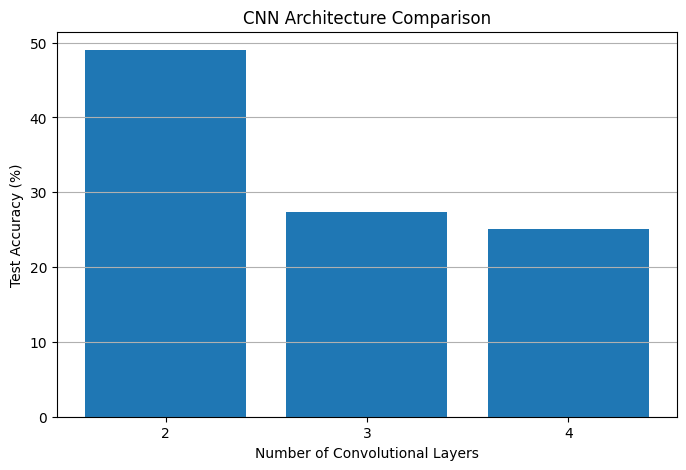

In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from tensorflow.keras import layers, models

# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Normalize images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

# Use smaller datasets to reduce memory and training time
x_train = x_train[:10000]
y_train = y_train[:10000]

x_val = x_train[:2000]
y_val = y_train[:2000]

x_train = x_train[2000:]
y_train = y_train[2000:]

x_test = x_test[:2000]
y_test = y_test[:2000]

# CNN configurations
configs = [
    {"layers": 2, "filters": 32, "kernel": 3, "batch_norm": False},
    {"layers": 3, "filters": 32, "kernel": 3, "batch_norm": True},
    {"layers": 4, "filters": 16, "kernel": 3, "batch_norm": True}
]

results = []

# Build and train models
for config in configs:

    tf.keras.backend.clear_session()

    model = models.Sequential()
    model.add(layers.Input(shape=(32, 32, 3)))

    filters = config["filters"]

    for i in range(config["layers"]):

        model.add(layers.Conv2D(
            filters * (2 ** i),
            config["kernel"],
            padding="same"
        ))

        if config["batch_norm"]:
            model.add(layers.BatchNormalization())

        model.add(layers.Activation("relu"))
        model.add(layers.MaxPooling2D(pool_size=(2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start = time.time()

    model.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=3,
        batch_size=64,
        verbose=1
    )

    loss, accuracy = model.evaluate(
        x_test, y_test, verbose=0
    )

    elapsed = time.time() - start

    results.append({
        "Conv Layers": config["layers"],
        "Filters": config["filters"],
        "Kernel Size": config["kernel"],
        "Batch Normalization": config["batch_norm"],
        "Test Accuracy": round(accuracy * 100, 2),
        "Parameters": model.count_params(),
        "Training Time": round(elapsed, 2)
    })

# Display comparison results
df = pd.DataFrame(results)

print("\nCNN MODEL COMPARISON RESULTS")
display(df)

# Plot accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(df["Conv Layers"].astype(str), df["Test Accuracy"])
plt.xlabel("Number of Convolutional Layers")
plt.ylabel("Test Accuracy (%)")
plt.title("CNN Architecture Comparison")
plt.grid(axis="y")
plt.show()